# Euler contributions, concentration and importance sampling

**Question:** Which group of the 1,120-name book owns its capital, how far is that from its exposure share, and can importance sampling reach the 99.9% tail with a fraction of the scenarios?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- say why the Euler contributions of the groups of a book add up to its total, and check it on a simulation: exactly for the expected shortfall, within a tolerance for the VaR;
- see that VaR contributions are noisier than expected-shortfall contributions, by repeating the simulation with different seeds;
- compare the contributions of a finite book with the closed-form asymptotic ones, and read what the difference says about concentration;
- compute the Herfindahl index and the effective number of names of a book;
- build an importance-sampling estimator for the tail with the exponential twist, check it is unbiased, and read its variance ratio against plain Monte Carlo.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# The notebook sits three folders below the repository root
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


# Names of the validation lights
LIGHTS = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The commercial and industrial file of case C10, `data/derived/C10/commercial-industrial.json` (owner: this repository; the loss rates behind its fit come from the Federal Reserve's table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, public domain, licence class `mirror-allowed`). It holds the **illustrative book** (`outputs.portfolio`: 20 large, 100 mid-size and 1,000 small names, 100 million USD, constructed for the case and never a bank's), the committed Euler contributions by group (`outputs.euler`) and the committed ladder (`outputs.rungs`, including the importance-sampling rung and its diagnostics). The next cell loads it and prints the groups of the book.

In [2]:
# Load the artifact and print the groups of the illustrative book
doc = json.loads((ROOT / "data" / "derived" / "C10" / "commercial-industrial.json").read_text(encoding="utf-8"))
out = doc["outputs"]
book = out["portfolio"]
groups = book["groups"]
pd_hat = out["fit"]["maximum_likelihood"]["pd"]["estimate"]
rho_hat = out["fit"]["maximum_likelihood"]["rho"]["estimate"]
rungs = {r["id"]: r for r in out["rungs"]}

for g in groups:
    print(f"{g['id']:9s} {g['n_names']:5d} names x {g['ead_each']:>11,.0f} | PD {g['pd']:.5f}")

g-large      20 names x   2,000,000 | PD 0.00506
g-mid       100 names x     400,000 | PD 0.01012
g-small    1000 names x      20,000 | PD 0.01517


## Method

### Step 1: Euler contributions and why they add up

A bank wants to know how much of the book's capital each group is responsible for. For a risk measure $\rho$ that is positively homogeneous (scaling every exposure by $c$ scales the risk by $c$), the **Euler principle** gives the contribution of group $g$ as the derivative of the risk with respect to its size, and the contributions add up to the total (Tasche, 2008, https://arxiv.org/abs/0708.2542). For the two measures of the case they are conditional expectations of the group's loss $L_g$ given the total $L$:

$$\mathrm{RC}_g^{\mathrm{VaR}}=E\big[L_g\mid L=\mathrm{VaR}_q(L)\big],\qquad \mathrm{RC}_g^{\mathrm{ES}}=E\big[L_g\mid L\ge \mathrm{VaR}_q(L)\big]$$

On a simulation the ES contribution is an average over the tail scenarios, with the Acerbi and Tasche weights of notebook 03, so the contributions add up to the sample ES exactly. The VaR contribution conditions on one loss level, which almost no scenario hits, so it is noisy; the engine smooths it with the kernel estimator of Tasche (2009, https://doi.org/10.1080/14697680802620599), a Nadaraya-Watson average with a Gaussian kernel at the sample VaR and Silverman's bandwidth $1.06\,\mathrm{sd}(L)\,S^{-1/5}$ (the bandwidth is the engine's choice; the paper names none). The kernel estimate is biased at the boundary, so its sum matches the VaR within a stated tolerance, not exactly. The engine's `euler_additivity` tests that sum: green when the relative gap is within the tolerance, red above, with no amber. The next cell simulates the book with the losses of each group kept, computes both contributions at 99% and 99.9%, and tests their sums, with the tolerances the pipeline uses: $10^{-6}$ for ES and 0.01 for VaR.

In [3]:
# Simulate the book keeping the losses of each group, compute both contributions and test that they add up
from riskvalidation.portfolio import copula, euler
from riskvalidation.portfolio import portfolio as pf
from riskvalidation.validation.portfolio import euler_additivity

one = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], one_factor=True)
el = pf.expected_loss(one)
sim = rungs["c2-gaussian-1f"]["simulation"]
sample = copula.simulate_gaussian(one, 100_000, sim["seed"], sim["chunk_size"], track_groups=True)
measures = pf.measures_from_sample(sample.losses, (0.99, 0.999), el)
tolerance = {"var": 0.01, "es": 1e-6}
print("scenarios:", sample.n_scenarios, "| group losses:", sample.group_losses.shape)

contributions = {}
for m in measures:
    rc_es = euler.es_contributions(sample.group_losses, sample.losses, m.level)
    rc_var = euler.var_contributions_kernel(sample.group_losses, sample.losses, m.level)
    contributions[m.level] = (rc_var, rc_es)
    test_es = euler_additivity(rc_es, m.es, tolerance["es"], model_id="gaussian-1f", segment=f"es-{m.level}")
    test_var = euler_additivity(rc_var, m.var, tolerance["var"], model_id="gaussian-1f", segment=f"var-{m.level}")
    print(f"q = {m.level}: ES {m.es:,.0f} | sum of contributions: {rc_es.sum():,.0f}")
    print(f"        gap: {test_es.metric:.1e} | {LIGHTS[test_es.light.value]}")
    print(f"        VaR {m.var:,.0f} | sum of contributions: {rc_var.sum():,.0f}")
    print(f"        gap: {test_var.metric:.1e} | {LIGHTS[test_var.light.value]}")

scenarios: 100000 | group losses: (100000, 3)
q = 0.99: ES 2,535,057 | sum of contributions: 2,535,057
        gap: 1.3e-15 | green
        VaR 2,088,000 | sum of contributions: 2,087,480
        gap: 2.5e-04 | green
q = 0.999: ES 3,609,180 | sum of contributions: 3,609,180
        gap: 1.3e-16 | green
        VaR 3,087,000 | sum of contributions: 3,082,159
        gap: 1.6e-03 | green


The contributions by group, as shares of the total, say who the capital belongs to. The next cell computes those three shares at 99.9% for each group and draws them as bars.

exposure       0.400   0.400   0.200
VaR            0.591   0.269   0.139
ES             0.576   0.275   0.149


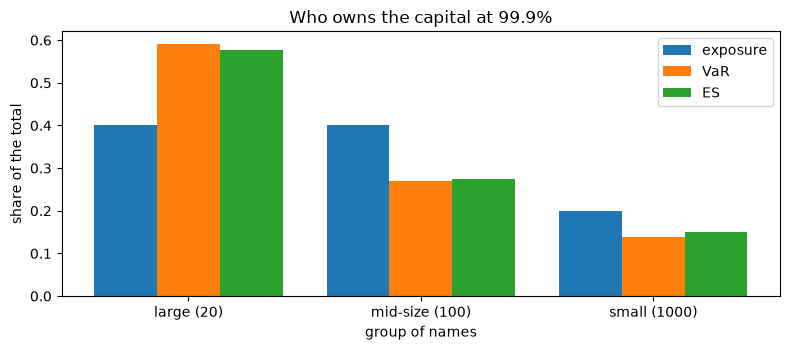

In [4]:
# Compute the exposure, VaR and ES shares of each group at 99.9% and draw them
rc_var_999, rc_es_999 = contributions[0.999]
exposure = np.array([g["n_names"] * g["ead_each"] for g in groups])
shares = {
    "exposure": exposure / exposure.sum(),
    "VaR": rc_var_999 / rc_var_999.sum(),
    "ES": rc_es_999 / rc_es_999.sum(),
}
group_labels = ["large (20)", "mid-size (100)", "small (1000)"]
for name, values in shares.items():
    print(f"{name:12s}", " ".join(f"{v:7.3f}" for v in values))

fig, ax = plt.subplots(figsize=(8, 3.6))
position = np.arange(len(groups))
for k, (name, values) in enumerate(shares.items()):
    ax.bar(position + 0.27 * (k - 1), values, width=0.27, label=name)
ax.set_xticks(position, group_labels)
ax.set_xlabel("group of names")
ax.set_ylabel("share of the total")
ax.set_title("Who owns the capital at 99.9%")
ax.legend()
fig.tight_layout()
plt.show()

The first bar of each group is its share of the exposure, the others its share of the risk. The 20 large names are 40% of the exposure and carry nearly 60% of both capital measures, while the 1,000 small names are 20% of the exposure and carry about 14%. The VaR and ES shares tell the same story in the same order, which is reassuring because they come from different estimators. What the figure shows is where the book is concentrated; what it does not show is how reliable each share is, since it comes from one sample of 100,000 scenarios. The next step repeats the simulation to measure that noise.

### Step 2: the noise of VaR contributions

How much do the contributions move from one simulation to the next? The next cell repeats the simulation six times with 50,000 scenarios and a different seed each, and computes the share of each group in the 99.9% total three ways: the ES contribution; the kernel VaR contribution; and a plain estimate of the definition, the average group loss over the scenarios whose total is within 2% of the VaR (a check of the definition, written inline, not an engine method). It prints the mean share across the six runs and the coefficient of variation, the standard deviation over the mean.

In [5]:
# Repeat the simulation with six seeds and compare three estimates of the group shares
runs = {"ES": [], "VaR (kernel)": [], "VaR (plain band)": []}
for seed in range(900, 906):
    run = copula.simulate_gaussian(one, 50_000, seed, sim["chunk_size"], track_groups=True)
    m = pf.measures_from_sample(run.losses, (0.999,), el)[0]
    in_band = np.abs(run.losses - m.var) <= 0.02 * m.var
    estimates = (
        euler.es_contributions(run.group_losses, run.losses, 0.999),
        euler.var_contributions_kernel(run.group_losses, run.losses, 0.999),
        run.group_losses[in_band].mean(axis=0),
    )
    for key, values in zip(runs, estimates):
        runs[key].append(values / values.sum())

print(f"{'':22s} " + " ".join(f"{label:>18s}" for label in group_labels))
for key, repeated in runs.items():
    arr = np.array(repeated)
    cv = arr.std(axis=0, ddof=1) / arr.mean(axis=0)
    cells = [f"{arr.mean(axis=0)[k]:7.3f} (cv {cv[k]:.3f})" for k in range(len(groups))]
    print(f"{key:22s} " + " ".join(cells))

                               large (20)     mid-size (100)       small (1000)
ES                       0.539 (cv 0.041)   0.304 (cv 0.057)   0.157 (cv 0.047)
VaR (kernel)             0.557 (cv 0.054)   0.284 (cv 0.082)   0.159 (cv 0.067)
VaR (plain band)         0.552 (cv 0.061)   0.289 (cv 0.088)   0.159 (cv 0.076)


### Step 3: the asymptotic contributions and concentration

For an infinitely granular one-factor book the VaR contribution of name $i$ has a closed form: the loss is monotone in the factor, so the VaR is the conditional mean loss at the factor quantile $z=\Phi^{-1}(1-q)$, and $\mathrm{RC}_i=\mathrm{EAD}_i\,\mathrm{LGD}_i\,p_i(z)$ with $p_i$ the conditional PD of notebook 01 (Emmer and Tasche, 2005, https://arxiv.org/abs/cond-mat/0302402; the engine's `asrf_var_contributions` states that this is the leading, portfolio-invariant term, not their full contribution, which adds granularity terms). These contributions depend on the name only through its own PD and exposure, whatever the rest of the book is. A finite book departs from them by concentration. The engine measures concentration by the Herfindahl index $\mathrm{HHI}=\sum_i s_i^2$ of the exposure shares and the effective number of names $1/\mathrm{HHI}$, which equals $N$ for $N$ equal names and 1 for a single name. The next cell computes the asymptotic contributions by group, compares them with the simulated ones, and prints the concentration of the book and of the same book with equal exposures.

In [6]:
# Compute the asymptotic contributions by group and the concentration of the book
cut = np.cumsum([0] + [g["n_names"] for g in groups])
asymptotic = euler.asrf_var_contributions(one.ead, one.pd, one.lgd, rho_hat, 0.999)
by_group = np.array([asymptotic[a:b].sum() for a, b in zip(cut[:-1], cut[1:])])
asymptotic_share = by_group / by_group.sum()
print("asymptotic VaR at 99.9%:", f"{asymptotic.sum():,.0f}")
for k, g in enumerate(groups):
    print(f"{g['id']:9s} {by_group[k]:12,.0f} {asymptotic_share[k]:8.3f}", end=" ")
    print(f"simulated share: {shares['VaR'][k]:.3f}")

equal = np.full(one.ead.size, one.ead.sum() / one.ead.size)
print("HHI:", euler.hhi(one.ead), "| effective names:", round(euler.effective_names(one.ead), 2))
print("same total, equal exposures: HHI", round(euler.hhi(equal), 6))
print("effective names:", round(euler.effective_names(equal), 1))

asymptotic VaR at 99.9%: 2,259,748
g-large        576,288    0.255 simulated share: 0.591
g-mid          998,871    0.442 simulated share: 0.269
g-small        684,590    0.303 simulated share: 0.139
HHI: 0.00964 | effective names: 103.73
same total, equal exposures: HHI 0.000893
effective names: 1120.0


The next cell draws, for each group, its share of the 99.9% VaR in the simulation and in the closed-form asymptotic contribution.

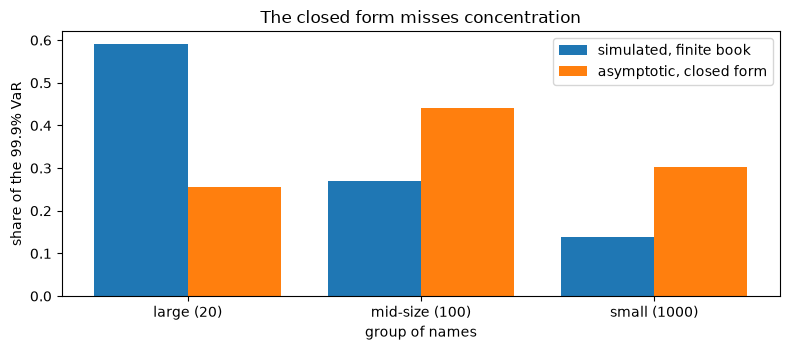

In [7]:
# Draw the simulated and the asymptotic VaR share of each group
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(position - 0.2, shares["VaR"], width=0.4, label="simulated, finite book")
ax.bar(position + 0.2, asymptotic_share, width=0.4, label="asymptotic, closed form")
ax.set_xticks(position, group_labels)
ax.set_xlabel("group of names")
ax.set_ylabel("share of the 99.9% VaR")
ax.set_title("The closed form misses concentration")
ax.legend()
fig.tight_layout()
plt.show()

The two bars of each group disagree in opposite directions for the large and the mid-size names: the closed form gives the 20 large names about a quarter of the capital where the simulation gives them about six tenths, and gives the mid-size names far more than the simulation does. The closed form uses each name's own PD and exposure and assumes infinitely many other names to diversify it, so it cannot see that 20 names of 2 million USD are lumpy. The simulation sees it because it draws each name. The figure compares shares of the same total risk at one confidence level, and says nothing about which share is right for a bank, only that concentration redistributes capital among the groups.

### Step 4: importance sampling for the tail

To estimate a 99.9% quantile by plain Monte Carlo, only 0.1% of the scenarios fall in the tail, and the batch-means errors of notebook 03 were large. **Importance sampling** draws the scenarios from a distribution that visits the tail more often and corrects each by a likelihood ratio. For the Gaussian copula with uncorrelated factors, the exponential twist of Glasserman and Li (2005, https://doi.org/10.1287/mnsc.1050.0415) works in two parts. Given the systematic factor $z$, each conditional default probability $p_i(z)$ is tilted, with $c_i=\mathrm{EAD}_i\,\mathrm{LGD}_i$ the loss of name $i$:

$$p_{i,\theta}(z)=\frac{p_i(z)\,e^{\theta c_i}}{1+p_i(z)\,(e^{\theta c_i}-1)},\qquad \theta=\theta(z)\ \text{the root of}\ \sum_i c_i\,p_{i,\theta}(z)=x$$

so that the tilted conditional mean loss equals the threshold $x$ (and $\theta=0$ where the untilted mean is already above it); then the factor itself is drawn with a shifted mean $\mu$. Each scenario carries the weight $w=\exp\!\big(-\theta L+\sum_i\ln(1+p_i(e^{\theta c_i}-1))\big)\exp\!\big(-\mu z+\mu^2/2\big)$ in the one-factor case, with $E_Q[w]=1$ and $E_Q[wL]=\mathrm{EL}$ for any $\theta(z)\ge0$ and any $\mu$: the estimator is unbiased whatever the tilt, and only its variance depends on it. A caution from the research: the dossier marks its transcription of the twist and of the mean shift as UNVERIFIED against the paper, which is paywalled, so the engine accepts nothing on trust and its acceptance is the unbiasedness checked against plain Monte Carlo, which we repeat below. The next cell takes one scenario, the factor value of the case's own shift, and shows the twist at work: the conditional default probabilities before and after, and the check that the tilted mean loss equals the target. The target is the plain Monte Carlo 99.9% VaR of Step 1.

In [8]:
# Show the exponential twist for one factor value: conditional default probabilities before and after
from riskvalidation.engines.vasicek import conditional_pd
from riskvalidation.portfolio import importance

threshold = measures[1].var
shift = next(p["value"] for p in rungs["c6-is-gaussian"]["parameters"] if p["name"] == "factor_shift")
loss_of_name = one.ead * one.lgd
p_group = [float(conditional_pd(g["pd"], rho_hat, shift)) for g in groups]
p_cond = np.repeat(p_group, [g["n_names"] for g in groups])
theta = importance.solve_theta(p_cond, loss_of_name, threshold)
p_twist = importance.twisted_pd(p_cond, loss_of_name, theta)

print("target loss (plain Monte Carlo VaR at 99.9%):", f"{threshold:,.0f}")
print("factor value:", round(shift, 4), "| theta:", f"{theta:.3e}")
print("mean loss given the factor, untilted:", f"{loss_of_name @ p_cond:,.0f}")
print("mean loss given the factor, tilted:", f"{loss_of_name @ p_twist:,.0f}")
for k, g in enumerate(groups):
    print(f"{g['id']:9s} before: {p_cond[cut[k]]:.4f} | after the twist: {p_twist[cut[k]]:.4f}")

target loss (plain Monte Carlo VaR at 99.9%): 3,087,000
factor value: -2.3235 | theta: 1.822e-06
mean loss given the factor, untilted: 1,479,392
mean loss given the factor, tilted: 3,087,000
g-large   before: 0.0201 | after the twist: 0.0956
g-mid     before: 0.0364 | after the twist: 0.0499
g-small   before: 0.0513 | after the twist: 0.0521


The next cell draws the conditional default probability of each group before and after the twist.

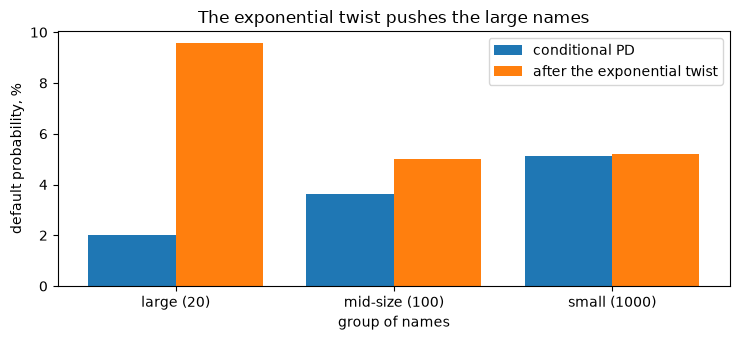

In [9]:
# Draw the conditional default probability of each group before and after the twist
before = np.array([p_cond[cut[k]] for k in range(len(groups))])
after = np.array([p_twist[cut[k]] for k in range(len(groups))])

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.bar(position - 0.2, 100 * before, width=0.4, label="conditional PD")
ax.bar(position + 0.2, 100 * after, width=0.4, label="after the exponential twist")
ax.set_xticks(position, group_labels)
ax.set_xlabel("group of names")
ax.set_ylabel("default probability, %")
ax.set_title("The exponential twist pushes the large names")
ax.legend()
fig.tight_layout()
plt.show()

The twist is not uniform. The large names, which carry the largest loss per default, see their conditional default probability multiplied several times, the mid-size names rise moderately and the small names barely move. That is the right allocation of effort: to reach a loss of 3 million USD the simulation needs defaults among the lumpy names, so it makes those defaults frequent and then corrects with the weights. The bars show one factor value; the estimator applies the construction at the factor values it draws. A twist chosen badly would still be unbiased, only slower, which is what the next step checks against plain Monte Carlo.

The twist pushes the large names hardest, because they carry the largest losses. Now the estimator. The next cell draws 20,000 importance-sampling scenarios with the seed of the case and the plain Monte Carlo VaR as the target, and checks what the theory promises: the factor shift the engine solved, the mean of the weights (1 in expectation), and the weighted mean loss (the expected loss in expectation). It then reads the VaR and ES at 99% and 99.9% with `weighted_var_es`, which normalises the tail by the scenario count and never by the realised sum of the weights, and puts them beside the plain Monte Carlo of notebook 03's 100,000 scenarios.

In [10]:
# Draw 20,000 importance-sampling scenarios, check the unbiasedness identities and read VaR and ES
n_is = 20_000
seed_is = rungs["c6-is-gaussian"]["simulation"]["seed"]
result = importance.importance_sample_gaussian(one, threshold, n_is, seed_is, None, sim["chunk_size"])
w = result.weights
print("factor shift solved by the engine:", round(float(result.factor_shift[0]), 6))
print("mean of the weights (1 in expectation):", round(float(w.mean()), 4))
print("weighted mean loss:", f"{float(np.mean(w * result.losses)):,.0f}", "| EL:", f"{el:,.0f}")
print("effective sample share:", round(float(w.sum() ** 2 / (w.size * np.sum(w * w))), 5))

plain = {m.level: m for m in measures}
is_se = {}
print(f"{'q':>6s} {'VaR IS':>12s} {'error':>9s} {'VaR plain':>16s} {'error':>9s}")
for q in (0.99, 0.999):
    var_i, es_i, se_v, se_e = importance.weighted_var_es(result, q)
    is_se[q] = (se_v, se_e)
    print(f"{q:6.3f} {var_i:12,.0f} {se_v:9,.0f} {plain[q].var:16,.0f} {plain[q].var_se:9,.0f}")
    print(f"       ES IS {es_i:12,.0f} {se_e:9,.0f} | ES plain: {plain[q].es:12,.0f} {plain[q].es_se:9,.0f}")

factor shift solved by the engine: -2.271303
mean of the weights (1 in expectation): 0.5522
weighted mean loss: 335,666 | EL: 409,721
effective sample share: 0.0024
     q       VaR IS     error        VaR plain     error
 0.990    2,106,000     7,788        2,088,000    18,433
       ES IS    2,577,016     3,389 | ES plain:    2,535,057    24,792
 0.999    3,204,000     6,953        3,087,000    54,340
       ES IS    3,701,551     5,585 | ES plain:    3,609,180    87,336


The variance ratio is the number of plain Monte Carlo scenarios that one importance-sampling scenario is worth. The engine's `variance_ratio` is $(\mathrm{se}_{\text{plain}}/\mathrm{se}_{\text{IS}})^2$ at equal sample size, so the plain error from 100,000 scenarios is first scaled to 20,000 by $\sqrt{100{,}000/20{,}000}$. The next cell computes it for the 99.9% VaR and ES and draws the standard errors of both estimators at 20,000 scenarios.

variance ratio, VaR 99.9%: 305
variance ratio, ES 99.9%: 1223
each importance-sampling scenario is worth about 305 plain scenarios for the VaR


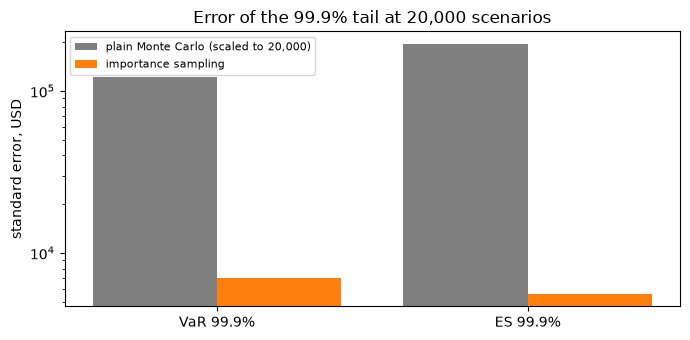

In [11]:
# Compute the variance ratio against plain Monte Carlo at equal sample size and draw the two errors
scale = math.sqrt(100_000 / n_is)
plain_se = (plain[0.999].var_se * scale, plain[0.999].es_se * scale)
ratio_var = importance.variance_ratio(plain_se[0], is_se[0.999][0])
ratio_es = importance.variance_ratio(plain_se[1], is_se[0.999][1])
print("variance ratio, VaR 99.9%:", round(ratio_var))
print("variance ratio, ES 99.9%:", round(ratio_es))
print("each importance-sampling scenario is worth about", round(ratio_var), "plain scenarios for the VaR")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(np.arange(2) - 0.2, plain_se, width=0.4, color="tab:gray", label="plain Monte Carlo (scaled to 20,000)")
ax.bar(np.arange(2) + 0.2, is_se[0.999], width=0.4, color="tab:orange", label="importance sampling")
ax.set_xticks(range(2), ["VaR 99.9%", "ES 99.9%"])
ax.set_yscale("log")
ax.set_ylabel("standard error, USD")
ax.set_title("Error of the 99.9% tail at 20,000 scenarios")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The orange bars are one to two orders of magnitude below the grey ones on a logarithmic axis, for the VaR and for the expected shortfall alike. At equal sample size the importance-sampling estimator is therefore many times more precise, and the variance ratio printed above translates that into the number of plain scenarios each of its own is worth. The gain is largest where the tail is rarest, which is the 99.9% level that capital uses. The figure compares errors that are themselves batch estimates, so the ratios are orders of magnitude, not exact constants, and a different seed would move them. The engine has no twist for the Student t copula, so this gain does not carry over to that model.

## Results

**Answer:** the 20 large names own 59.1% of the 99.9% value at risk of 3,087,000 USD while they are 40% of the exposure, and importance sampling reaches that tail with a standard error of 6,953 USD at 20,000 scenarios, where plain Monte Carlo at 100,000 scenarios has 54,340 USD: each importance-sampling scenario is worth about 305 plain ones for the VaR.

- **The contributions add up, exactly for ES and within tolerance for VaR.** The ES contributions of the three groups sum to the sample ES with a relative gap of 1.3e-15 at 99% and 1.3e-16 at 99.9%, both green: the Acerbi and Tasche weights make the sum an identity. The kernel VaR contributions sum to 2,087,480 against a VaR of 2,088,000 at 99% (gap 2.5e-4) and to 3,082,159 against 3,087,000 at 99.9% (gap 1.6e-3), both inside the 0.01 tolerance and green. A gap below the tolerance is not zero, and the test is a gate of Contraste, not a regulatory threshold.
- **The large names carry far more capital than their exposure.** The 20 large names are 40% of the exposure and carry 59.1% of the 99.9% VaR and 57.6% of the ES. The mid-size names are 40% of the exposure and carry 26.9% of the VaR, the 1,000 small names 20% of the exposure and 13.9%.
- **VaR contributions are noisier than ES contributions, though at 50,000 scenarios not by much.** Across six seeds the coefficient of variation of the 99.9% share of the large names is 4.1% for the ES contribution, 5.4% for the kernel VaR contribution and 6.1% for the plain estimate from scenarios near the VaR, and the same order holds for the mid-size and small names (5.7%, 8.2%, 8.8% and 4.7%, 6.7%, 7.6%). The kernel smooths the plain estimate, and the ES contribution is steadier than both.
- **The asymptotic contributions cannot see concentration.** The closed-form ASRF contributions add to 2,259,748 USD at 99.9% and give the large names 25.5% of the capital against the simulated 59.1%, and the mid-size names 44.2% against 26.9%. They depend on each name only through its own PD and exposure, so they are portfolio-invariant: a name of 2 million USD gets the same capital per dollar in a book of 1,120 names and in a book of 20. The finite book concentrates capital in its largest names, and a closed form that ignores the rest of the book misses it.
- **Concentration in one number.** The Herfindahl index is 0.00964 and the effective number of names 103.73 of the 1,120; the same total spread over equal exposures would be 0.000893 and 1,120 effective names. The largest name is 2% of the exposure.
- **The exponential twist moves the loss where the tail is.** For the factor value -2.3235 the mean loss given the factor is 1,479,392 USD untilted and, after solving for theta (1.822e-6), 3,087,000 USD, the target. The twist raises the conditional default probability of the large names from 2.01% to 9.56%, the mid-size from 3.64% to 4.99% and the small from 5.13% to 5.21%: it pushes where the loss per name is largest.
- **The estimator is unbiased in expectation, and the sample shows what that means.** At 20,000 scenarios the weights average 0.5522, not 1, and the weighted mean loss is 335,666 USD against the expected loss of 409,721 USD: the weights are heavy-tailed and a sample of 20,000 is far from their mean (the effective sample share is 0.24%). This is the reason `weighted_var_es` normalises the tail by the number of scenarios and never by the realised sum of the weights. The 99.9% VaR is 3,204,000 USD with a standard error of 6,953, which is 117,000 USD above the plain run's 3,087,000 ± 54,340, about two plain standard errors. The ES is 3,701,551 ± 5,585 against 3,609,180 ± 87,336. The test of the twist is this agreement, because the dossier marks the transcription of the twist as unverified against the paper.
- **The gain is large.** At equal sample size each importance-sampling scenario is worth about 305 plain scenarios for the 99.9% VaR and about 1,223 for the ES. The ratios move from run to run because both errors are batch-means estimates and the tail errors are themselves noisy.

What this notebook does not show: Student t importance sampling (the engine has no twist for it), the multi-factor twist (the engine supports only uncorrelated factors), or the contributions of single names rather than groups.

## Summary

- Euler contributions split capital among groups and add up to the total: exactly for expected shortfall (`es_contributions`), within a stated tolerance for VaR (`var_contributions_kernel`), checked by `euler_additivity`.
- VaR contributions are the noisier of the two; the kernel smooths them but they stay noisier than the ES contributions.
- The asymptotic contributions (`asrf_var_contributions`) are portfolio-invariant and miss concentration: the large names carry far more capital in the finite book than the closed form gives them. `hhi` and `effective_names` measure the concentration.
- Importance sampling with the exponential twist (`solve_theta`, `twisted_pd`, `importance_sample_gaussian`, `weighted_var_es`) reaches the 99.9% tail with hundreds of times less variance, and its unbiasedness is the acceptance test while the transcription of the twist is unverified.

**What to try next.** Change the seeds of Step 2 and watch the ranking of the three estimators hold. Then open notebook 06, where the tests of this battery are read together on all five loan types.

## References

- Tasche, D. (2008), Capital allocation to business units and sub-portfolios: the Euler principle, arXiv 0708.2542. https://arxiv.org/abs/0708.2542
- Tasche, D. (2009), Capital allocation for credit portfolios with kernel estimators, Quantitative Finance 9(5):581-595. https://doi.org/10.1080/14697680802620599
- Emmer, S. and Tasche, D. (2005), Calculating credit risk capital charges with the one-factor model, Journal of Risk 7(2):85-101, arXiv cond-mat/0302402. https://arxiv.org/abs/cond-mat/0302402
- Glasserman, P. and Li, J. (2005), Importance sampling for portfolio credit risk, Management Science 51(11):1643-1656. https://doi.org/10.1287/mnsc.1050.0415
- Acerbi, C. and Tasche, D. (2002), On the coherence of expected shortfall, Journal of Banking and Finance 26(7):1487-1503. https://doi.org/10.1016/S0378-4266(02)00283-2
- Federal Reserve charge-off table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm (public domain; licence class mirror-allowed).
- Persisted research dossier 04 of this product (credit-risk models and current methods), sections H.2, H.6 and H.7 (Euler contributions, concentration and rare-event simulation; the transcription of the twist is marked UNVERIFIED there).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.